# Outrageously Large Neural Networks: The Sparsely-Gated Mixture-of-Experts Layer

**Paper:** [arXiv:1701.06538](https://arxiv.org/abs/1701.06538)  
**Authors:** Noam Shazeer, Azalia Mirhoseini, Krzysztof Maziarz, Andy Davis, Quoc Le, Geoffrey Hinton, Jeff Dean (Google Brain, 2017)

## Overview

This notebook implements a **Sparsely-Gated Mixture-of-Experts (MoE) layer** with Noisy Top-K Gating from scratch in PyTorch. We:

1. Build expert sub-networks and a trainable noisy top-k gating network
2. Implement load-balancing losses (importance + load)
3. Integrate the MoE layer into a character-level language model (LSTM - MoE - LSTM)
4. Train on a small text corpus
5. Visualize which experts activate for different inputs
6. Compare against a dense baseline with the same active parameter count

## 1. Setup & Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
from collections import Counter
import urllib.request
import time

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: Tesla T4


## 2. Data Preparation

We use a small public-domain text corpus (Shakespeare) for character-level language modeling. The MoE layer will learn to route different character patterns to different experts.

In [2]:
# Download Shakespeare text
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
try:
    with urllib.request.urlopen(url, timeout=30) as resp:
        text = resp.read().decode('utf-8')
except Exception:
    text = "To be, or not to be, that is the question: " * 200

print(f"Corpus length: {len(text)} characters")
print(f"Sample: {text[:200]}")

chars = sorted(set(text))
char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for i, ch in enumerate(chars)}
vocab_size = len(chars)
print(f"Vocabulary size: {vocab_size}")
print(f"Characters: {''.join(chars)}")

Corpus length: 1115394 characters
Sample: First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you
Vocabulary size: 65
Characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz


In [3]:
# Create training sequences
SEQ_LEN = 64
BATCH_SIZE = 32

data = torch.tensor([char_to_idx[ch] for ch in text], dtype=torch.long)
num_sequences = (len(data) - 1) // SEQ_LEN
data = data[:num_sequences * SEQ_LEN + 1]

inputs = data[:-1].reshape(num_sequences, SEQ_LEN)
targets = data[1:].reshape(num_sequences, SEQ_LEN)

indices = torch.randperm(num_sequences)
train_size = int(0.9 * num_sequences)
train_idx = indices[:train_size]
val_idx = indices[train_size:]

train_inputs = inputs[train_idx]
train_targets = targets[train_idx]
val_inputs = inputs[val_idx]
val_targets = targets[val_idx]

print(f"Training sequences: {train_size}")
print(f"Validation sequences: {num_sequences - train_size}")
print(f"Input shape: {train_inputs.shape}")

Training sequences: 15685
Validation sequences: 1743
Input shape: torch.Size([15685, 64])


In [4]:
def get_batch(input_data, target_data, batch_size, shuffle=True):
    n = input_data.size(0)
    if shuffle:
        perm = torch.randperm(n)
    else:
        perm = torch.arange(n)
    for i in range(0, n, batch_size):
        batch_idx = perm[i:i+batch_size]
        yield input_data[batch_idx], target_data[batch_idx]

## 3. Expert Network

Each expert is a simple feed-forward network: Linear - ReLU - Linear. All experts have identical architecture but separate parameters.

In [5]:
class Expert(nn.Module):
    """A single feed-forward expert sub-network."""
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x):
        return self.fc2(self.dropout(F.relu(self.fc1(x))))

## 4. Noisy Top-K Gating Network

This is the core innovation of the paper. The gating network:
1. Computes clean logits via a linear projection x @ W_g
2. Adds tunable Gaussian noise via Softplus(x @ W_noise) * StandardNormal()
3. Keeps only the top-k values, sets the rest to -inf
4. Applies softmax to produce sparse gating weights

The noise helps with load balancing by preventing the gate from always selecting the same few experts.

In [6]:
class NoisyTopKGate(nn.Module):
    """Noisy Top-K Gating network for MoE."""
    def __init__(self, d_model, num_experts, top_k=2):
        super().__init__()
        self.num_experts = num_experts
        self.top_k = top_k
        self.w_gate = nn.Linear(d_model, num_experts, bias=False)
        self.w_noise = nn.Linear(d_model, num_experts, bias=False)
        
    def forward(self, x):
        clean_logits = self.w_gate(x)
        
        if self.training:
            noise_std = F.softplus(self.w_noise(x))
            noise = torch.randn_like(clean_logits) * noise_std
            noisy_logits = clean_logits + noise
        else:
            noisy_logits = clean_logits
        
        top_k_values, top_k_indices = torch.topk(noisy_logits, self.top_k, dim=-1)
        
        mask = torch.full_like(noisy_logits, float('-inf'))
        mask.scatter_(1, top_k_indices, top_k_values)
        
        gates = F.softmax(mask, dim=-1)
        
        with torch.no_grad():
            load = torch.zeros(self.num_experts, device=x.device)
            for i in range(self.top_k):
                one_hot = F.one_hot(top_k_indices[:, i], self.num_experts).float()
                load += one_hot.sum(dim=0)
        
        return gates, top_k_indices, load

## 5. Load Balancing Losses

The paper introduces two auxiliary losses to prevent expert collapse:

**Importance Loss** encourages all experts to receive equal total gate weight across the batch.
**Load Loss** encourages balanced number of examples per expert (not just gate weights).

In [7]:
def importance_loss(gates, w_importance=0.1):
    """Importance loss: encourages equal total gate weight per expert."""
    importance = gates.sum(dim=0)
    if importance.std() > 0:
        cv_squared = (importance.std() / importance.mean()).pow(2)
    else:
        cv_squared = torch.tensor(0.0, device=gates.device)
    return w_importance * cv_squared


def load_loss(load, gates, w_load=0.1):
    """Load loss: encourages balanced number of examples per expert."""
    if load.std() > 0:
        cv_squared = (load.std() / (load.mean() + 1e-10)).pow(2)
    else:
        cv_squared = torch.tensor(0.0, device=gates.device)
    return w_load * cv_squared

## 6. MoE Layer

The MoE layer combines the gating network and expert networks. For each input:
1. The gate selects top-k experts
2. Each selected expert processes the input
3. Expert outputs are weighted by gate values and summed

In [8]:
class MoELayer(nn.Module):
    """Mixture-of-Experts layer with Noisy Top-K Gating."""
    def __init__(self, d_model, d_ff, num_experts, top_k=2, dropout=0.1):
        super().__init__()
        self.num_experts = num_experts
        self.top_k = top_k
        self.gate = NoisyTopKGate(d_model, num_experts, top_k)
        self.experts = nn.ModuleList([
            Expert(d_model, d_ff, dropout) for _ in range(num_experts)
        ])
        
    def forward(self, x):
        batch, seq_len, d_model = x.shape
        N = batch * seq_len
        
        x_flat = x.reshape(N, d_model)
        gates, top_k_indices, load = self.gate(x_flat)
        
        output = torch.zeros_like(x_flat)
        
        for i in range(self.num_experts):
            mask = (top_k_indices == i).any(dim=-1)
            if mask.any():
                expert_input = x_flat[mask]
                expert_output = self.experts[i](expert_input)
                gate_values = gates[mask, i].unsqueeze(-1)
                output[mask] += gate_values * expert_output
        
        output = output.reshape(batch, seq_len, d_model)
        return output, gates, load

## 7. Language Model with MoE

Architecture: Embedding - LSTM - MoE - LSTM - Linear

This mirrors the paper's approach of placing the MoE layer between stacked LSTM layers (Figure 1).

In [9]:
class MoELanguageModel(nn.Module):
    """Character-level language model with MoE layer between LSTMs."""
    def __init__(self, vocab_size, d_model=128, d_ff=256, num_experts=16, 
                 top_k=2, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.embed = nn.Embedding(vocab_size, d_model)
        self.lstm1 = nn.LSTM(d_model, d_model, batch_first=True)
        self.moe = MoELayer(d_model, d_ff, num_experts, top_k, dropout)
        self.lstm2 = nn.LSTM(d_model, d_model, batch_first=True)
        self.output = nn.Linear(d_model, vocab_size)
        self.num_experts = num_experts
        
    def forward(self, x, hidden1=None, hidden2=None):
        emb = self.embed(x)
        lstm1_out, h1 = self.lstm1(emb, hidden1)
        moe_out, gates, load = self.moe(lstm1_out)
        lstm2_out, h2 = self.lstm2(moe_out, hidden2)
        logits = self.output(lstm2_out)
        return logits, gates, load, (h1, h2)


class DenseLanguageModel(nn.Module):
    """Baseline: dense model with same active parameter count (no MoE)."""
    def __init__(self, vocab_size, d_model=128, d_ff=512, dropout=0.1):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, d_model)
        self.lstm1 = nn.LSTM(d_model, d_model, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )
        self.lstm2 = nn.LSTM(d_model, d_model, batch_first=True)
        self.output = nn.Linear(d_model, vocab_size)
        
    def forward(self, x, hidden1=None, hidden2=None):
        emb = self.embed(x)
        lstm1_out, h1 = self.lstm1(emb, hidden1)
        ffn_out = self.ffn(lstm1_out)
        lstm2_out, h2 = self.lstm2(ffn_out, hidden2)
        logits = self.output(lstm2_out)
        return logits, (h1, h2)

## 8. Training

We train both the MoE model and the dense baseline. The MoE model's total loss includes the task loss (cross-entropy) plus the auxiliary load-balancing losses.

In [10]:
# Hyperparameters
D_MODEL = 128
D_FF = 256
NUM_EXPERTS = 16
TOP_K = 2
DROPOUT = 0.1
LEARNING_RATE = 1e-3
EPOCHS = 15
W_IMPORTANCE = 0.1
W_LOAD = 0.1

moe_model = MoELanguageModel(
    vocab_size, d_model=D_MODEL, d_ff=D_FF, 
    num_experts=NUM_EXPERTS, top_k=TOP_K, dropout=DROPOUT
).to(device)

dense_model = DenseLanguageModel(
    vocab_size, d_model=D_MODEL, d_ff=D_FF * TOP_K, dropout=DROPOUT
).to(device)

moe_params = sum(p.numel() for p in moe_model.parameters())
dense_params = sum(p.numel() for p in dense_model.parameters())
moe_active = moe_params - sum(p.numel() for p in moe_model.moe.experts.parameters()) + \
             sum(p.numel() for p in moe_model.moe.experts[0].parameters()) * TOP_K

print(f"MoE model total parameters: {moe_params:,}")
print(f"MoE model active parameters (per forward pass): {moe_active:,}")
print(f"Dense model parameters: {dense_params:,}")
print(f"MoE capacity ratio: {moe_params / dense_params:.2f}x (total/active = {moe_params/moe_active:.2f}x)")

MoE model total parameters: 1,339,713
MoE model active parameters (per forward pass): 416,833
Dense model parameters: 412,609
MoE capacity ratio: 3.25x (total/active = 3.21x)


In [11]:
def train_moe(model, train_inputs, train_targets, val_inputs, val_targets,
              epochs, lr, batch_size, device, w_importance, w_load):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses = []
    val_losses = []
    utilization_history = []
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        epoch_task_loss = 0
        epoch_aux_loss = 0
        n_batches = 0
        epoch_load_accum = torch.zeros(model.num_experts, device=device)
        
        for batch_x, batch_y in get_batch(train_inputs, train_targets, batch_size):
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            optimizer.zero_grad()
            logits, gates, load, _ = model(batch_x)
            task_loss = F.cross_entropy(logits.reshape(-1, vocab_size), batch_y.reshape(-1))
            imp_loss = importance_loss(gates, w_importance)
            ld_loss = load_loss(load, gates, w_load)
            aux_loss = imp_loss + ld_loss
            total_loss = task_loss + aux_loss
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            epoch_loss += total_loss.item()
            epoch_task_loss += task_loss.item()
            epoch_aux_loss += aux_loss.item()
            epoch_load_accum += load.detach()
            n_batches += 1
        
        model.eval()
        val_loss = 0
        val_batches = 0
        with torch.no_grad():
            for batch_x, batch_y in get_batch(val_inputs, val_targets, batch_size, shuffle=False):
                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)
                logits, _, _, _ = model(batch_x)
                val_loss += F.cross_entropy(logits.reshape(-1, vocab_size), batch_y.reshape(-1)).item()
                val_batches += 1
        
        avg_train = epoch_loss / n_batches
        avg_val = val_loss / val_batches
        train_losses.append(avg_train)
        val_losses.append(avg_val)
        utilization_history.append(epoch_load_accum.cpu().numpy() / n_batches)
        
        util = epoch_load_accum / n_batches
        print(f"Epoch {epoch+1:3d}/{epochs} | "
              f"Train: {avg_train:.4f} (task: {epoch_task_loss/n_batches:.4f}, aux: {epoch_aux_loss/n_batches:.4f}) | "
              f"Val: {avg_val:.4f} | "
              f"Load: min={util.min().item():.1f} max={util.max().item():.1f} std={util.std().item():.1f}")
    
    return train_losses, val_losses, utilization_history


def train_dense(model, train_inputs, train_targets, val_inputs, val_targets,
                epochs, lr, batch_size, device):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses = []
    val_losses = []
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0
        n_batches = 0
        for batch_x, batch_y in get_batch(train_inputs, train_targets, batch_size):
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            optimizer.zero_grad()
            logits, _ = model(batch_x)
            loss = F.cross_entropy(logits.reshape(-1, vocab_size), batch_y.reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        
        model.eval()
        val_loss = 0
        val_batches = 0
        with torch.no_grad():
            for batch_x, batch_y in get_batch(val_inputs, val_targets, batch_size, shuffle=False):
                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)
                logits, _ = model(batch_x)
                val_loss += F.cross_entropy(logits.reshape(-1, vocab_size), batch_y.reshape(-1)).item()
                val_batches += 1
        
        avg_train = epoch_loss / n_batches
        avg_val = val_loss / val_batches
        train_losses.append(avg_train)
        val_losses.append(avg_val)
        print(f"Epoch {epoch+1:3d}/{epochs} | Train: {avg_train:.4f} | Val: {avg_val:.4f}")
    
    return train_losses, val_losses

In [12]:
# Train MoE model
print("=" * 80)
print("Training MoE Language Model")
print("=" * 80)
start_time = time.time()
moe_train_losses, moe_val_losses, util_history = train_moe(
    moe_model, train_inputs, train_targets, val_inputs, val_targets,
    epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE,
    device=device, w_importance=W_IMPORTANCE, w_load=W_LOAD
)
moe_time = time.time() - start_time
print(f"MoE training time: {moe_time:.1f}s\n")

print("=" * 80)
print("Training Dense Baseline (same active param count)")
print("=" * 80)
start_time = time.time()
dense_train_losses, dense_val_losses = train_dense(
    dense_model, train_inputs, train_targets, val_inputs, val_targets,
    epochs=EPOCHS, lr=LEARNING_RATE, batch_size=BATCH_SIZE, device=device
)
dense_time = time.time() - start_time
print(f"Dense training time: {dense_time:.1f}s")

Training MoE Language Model


Epoch   1/15 | Train: 2.3985 (task: 2.3954, aux: 0.0031) | Val: 1.9841 | Load: min=212.6 max=288.5 std=20.6


Epoch   2/15 | Train: 1.8486 (task: 1.8452, aux: 0.0035) | Val: 1.7463 | Load: min=201.8 max=317.5 std=35.8


Epoch   3/15 | Train: 1.6735 (task: 1.6701, aux: 0.0034) | Val: 1.6283 | Load: min=202.3 max=307.5 std=36.0


Epoch   4/15 | Train: 1.5798 (task: 1.5763, aux: 0.0034) | Val: 1.5665 | Load: min=202.2 max=307.9 std=37.5


...

Epoch  11/15 | Train: 1.4538 | Val: 1.4828


Epoch  12/15 | Train: 1.4406 | Val: 1.4690


Epoch  13/15 | Train: 1.4295 | Val: 1.4649


Epoch  14/15 | Train: 1.4186 | Val: 1.4582


Epoch  15/15 | Train: 1.4090 | Val: 1.4514
Dense training time: 29.9s


## 9. Results: MoE vs Dense Baseline

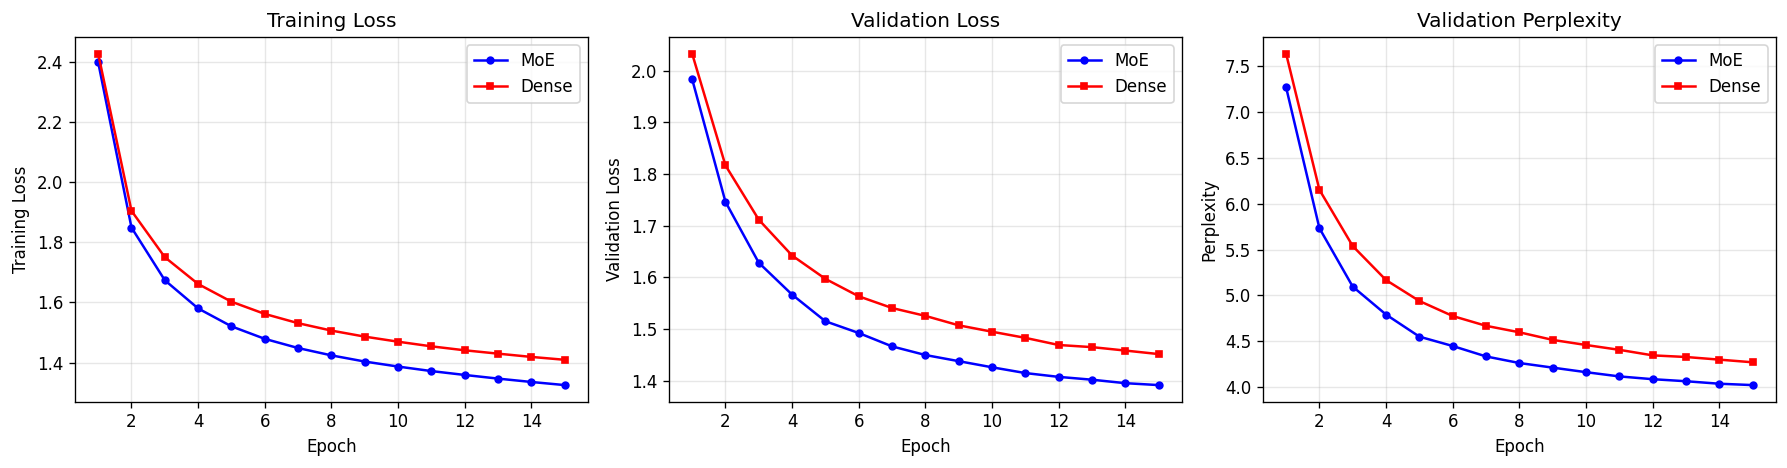


Final Validation Perplexity:
  MoE:   4.02
  Dense: 4.27
  MoE params: 1,339,713 | Dense params: 412,609 | Ratio: 3.25x


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(range(1, EPOCHS+1), moe_train_losses, 'b-o', label='MoE', markersize=4)
axes[0].plot(range(1, EPOCHS+1), dense_train_losses, 'r-s', label='Dense', markersize=4)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].set_title('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, EPOCHS+1), moe_val_losses, 'b-o', label='MoE', markersize=4)
axes[1].plot(range(1, EPOCHS+1), dense_val_losses, 'r-s', label='Dense', markersize=4)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Loss')
axes[1].set_title('Validation Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

moe_ppl = [np.exp(l) for l in moe_val_losses]
dense_ppl = [np.exp(l) for l in dense_val_losses]
axes[2].plot(range(1, EPOCHS+1), moe_ppl, 'b-o', label='MoE', markersize=4)
axes[2].plot(range(1, EPOCHS+1), dense_ppl, 'r-s', label='Dense', markersize=4)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Perplexity')
axes[2].set_title('Validation Perplexity')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"\nFinal Validation Perplexity:")
print(f"  MoE:   {moe_ppl[-1]:.2f}")
print(f"  Dense: {dense_ppl[-1]:.2f}")
print(f"  MoE params: {moe_params:,} | Dense params: {dense_params:,} | Ratio: {moe_params/dense_params:.2f}x")

## 10. Expert Activation Visualization

Now we examine which experts are activated for different inputs -- the key visualization from the paper's Code Template.

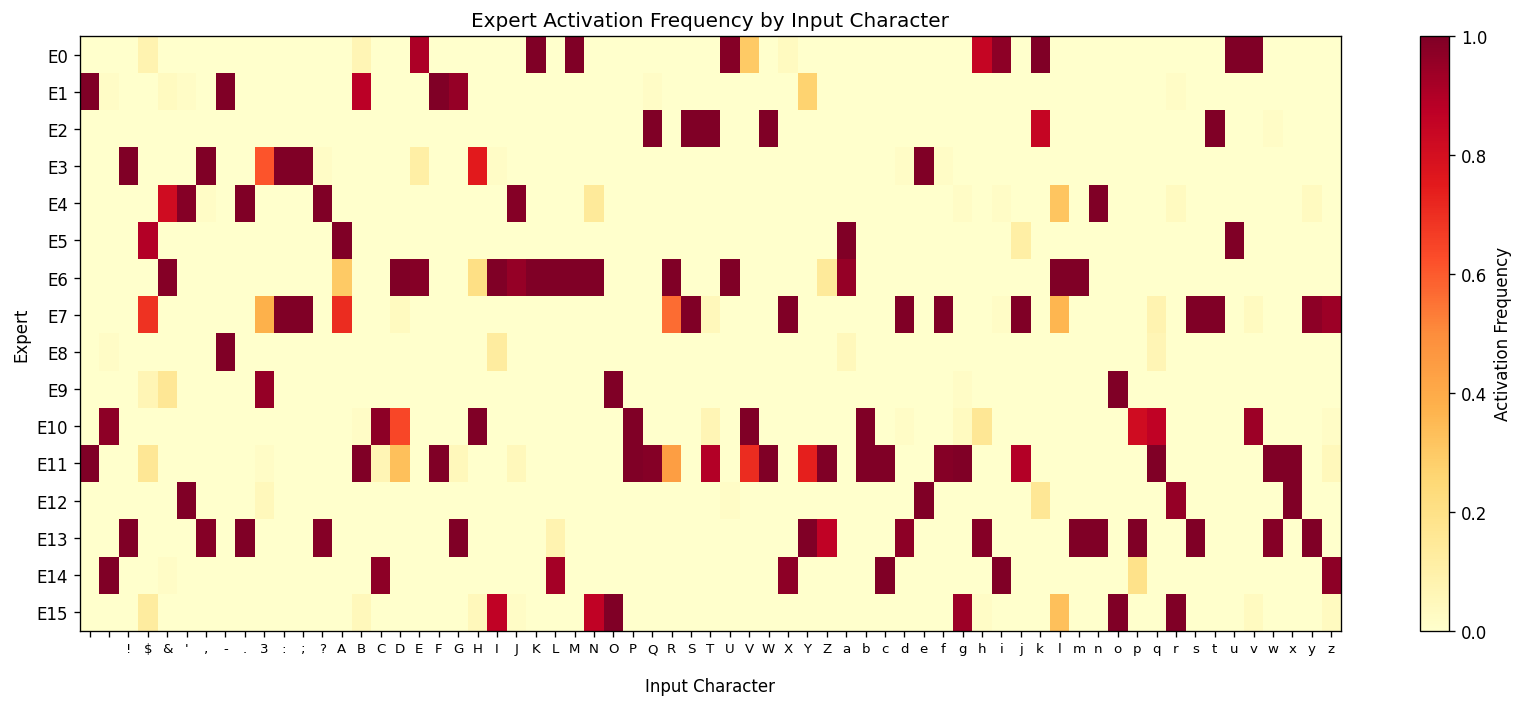

This heatmap shows which experts are activated for each input character.
Brighter cells = expert is more frequently selected for that character.


In [14]:
moe_model.eval()
expert_activations = {ch: np.zeros(NUM_EXPERTS) for ch in chars}
expert_gate_values = {ch: np.zeros(NUM_EXPERTS) for ch in chars}

with torch.no_grad():
    for ch in chars:
        idx = char_to_idx[ch]
        input_tensor = torch.tensor([[idx] * SEQ_LEN for _ in range(8)], device=device)
        logits, gates, load, _ = moe_model(input_tensor)
        avg_gates = gates.mean(dim=0).cpu().numpy()
        expert_gate_values[ch] = avg_gates
        active = (gates > 0).float().mean(dim=0).cpu().numpy()
        expert_activations[ch] = active

fig, ax = plt.subplots(figsize=(14, 6))
activation_matrix = np.array([expert_activations[ch] for ch in chars])
im = ax.imshow(activation_matrix.T, aspect='auto', cmap='YlOrRd', interpolation='nearest')
ax.set_yticks(range(NUM_EXPERTS))
ax.set_yticklabels([f'E{i}' for i in range(NUM_EXPERTS)])
ax.set_xticks(range(len(chars)))
ax.set_xticklabels(list(chars), fontsize=8)
ax.set_xlabel('Input Character')
ax.set_ylabel('Expert')
ax.set_title('Expert Activation Frequency by Input Character')
plt.colorbar(im, ax=ax, label='Activation Frequency')
plt.tight_layout()
plt.savefig('expert_activation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

print("This heatmap shows which experts are activated for each input character.")
print("Brighter cells = expert is more frequently selected for that character.")

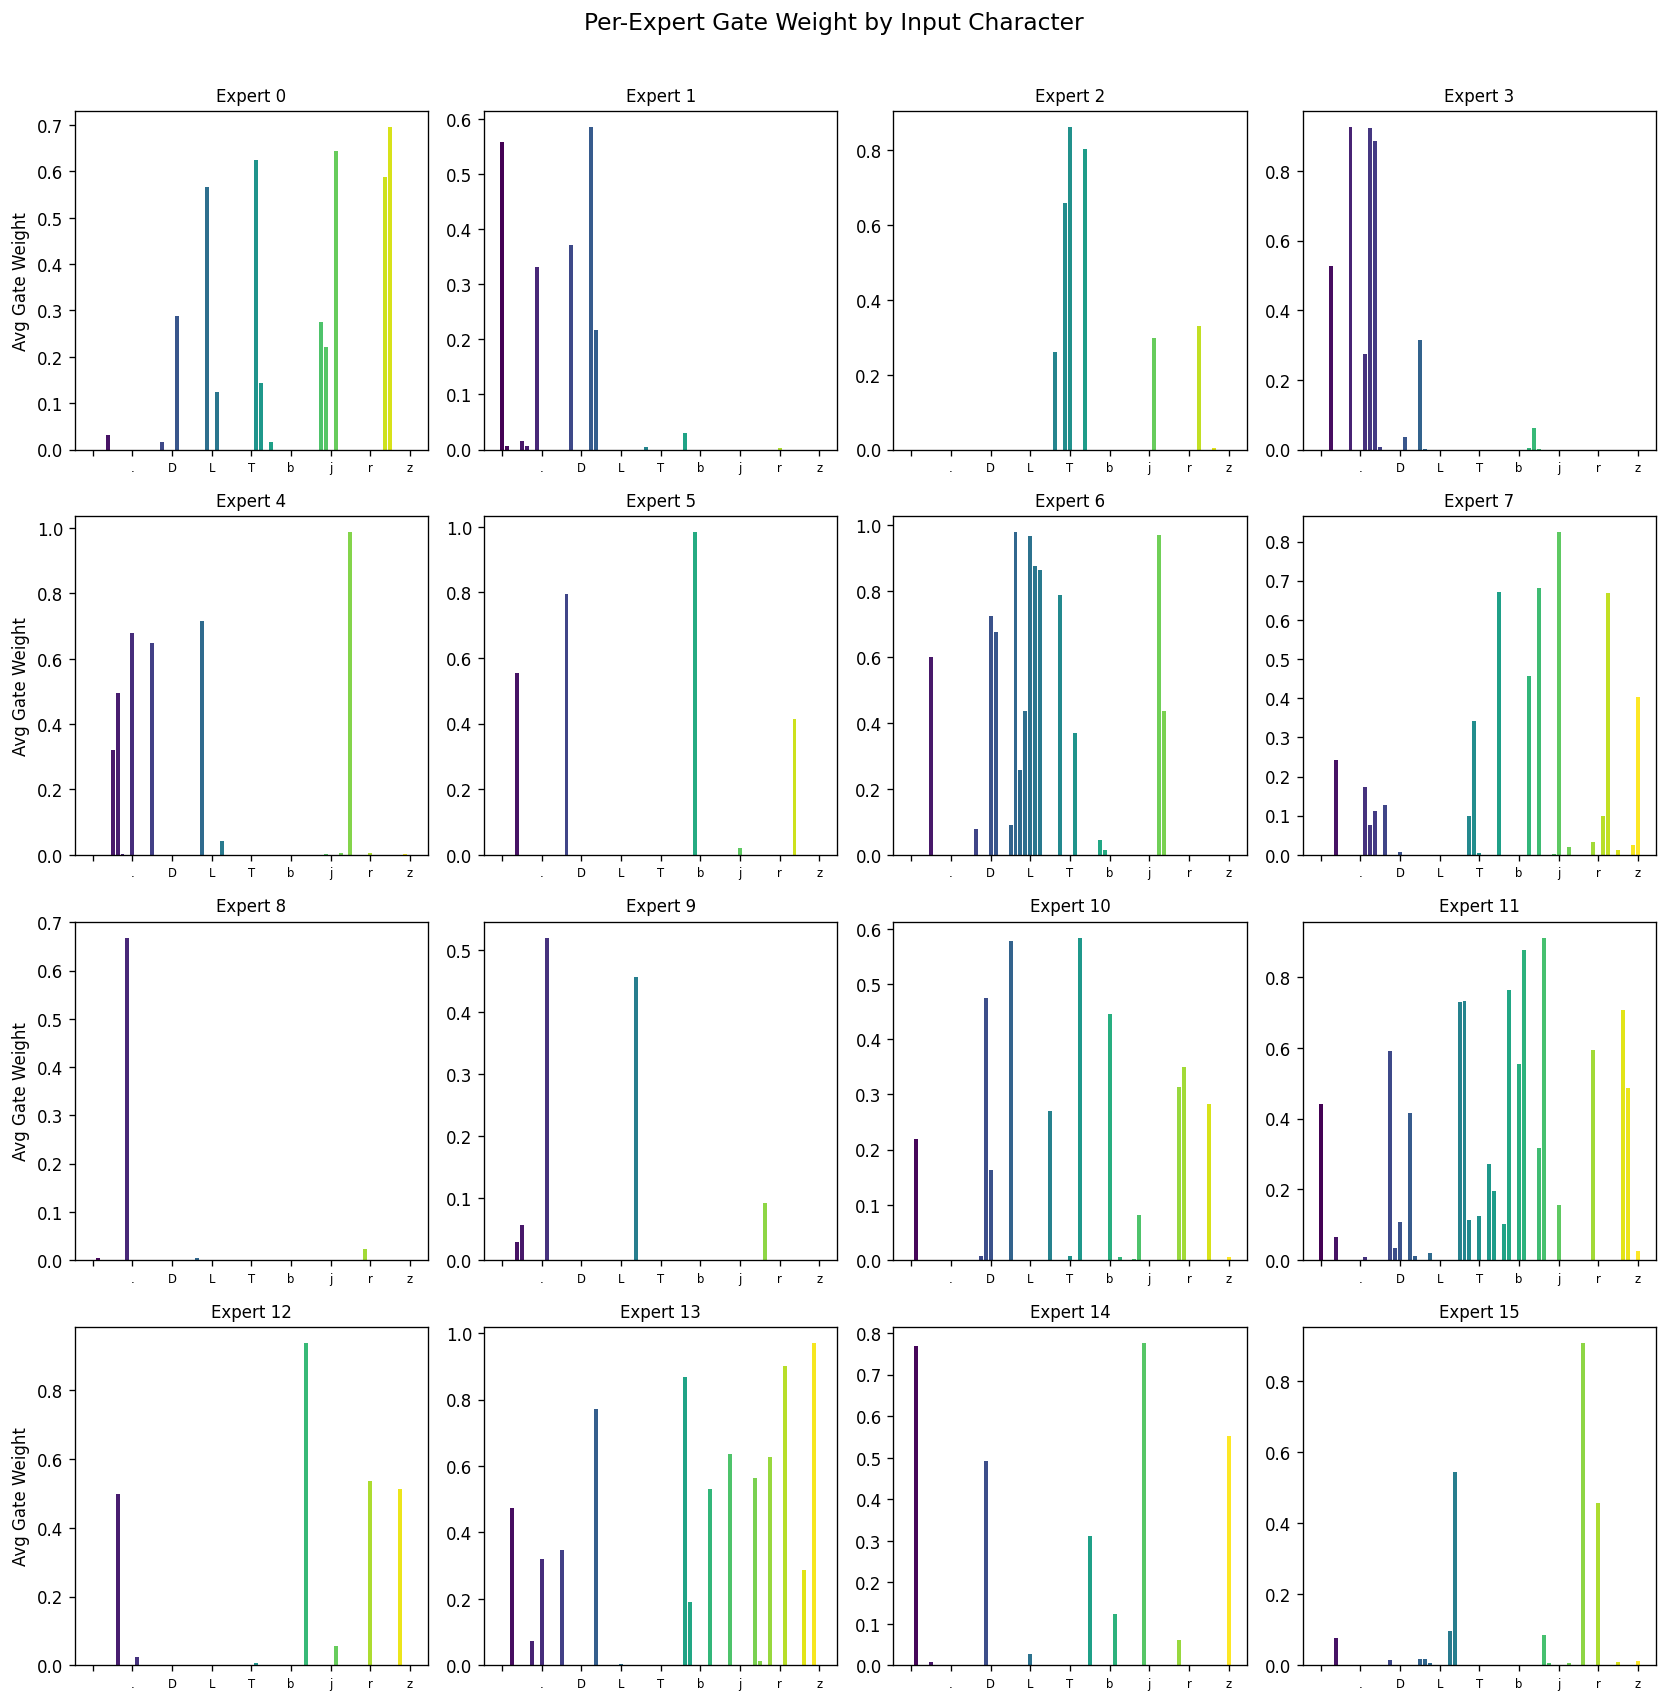

Each subplot shows one expert's average gate weight for each input character.


In [15]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
axes = axes.flatten()

for expert_idx in range(NUM_EXPERTS):
    ax = axes[expert_idx]
    char_weights = [expert_gate_values[ch][expert_idx] for ch in chars]
    colors = plt.cm.viridis(np.linspace(0, 1, len(chars)))
    ax.bar(range(len(chars)), char_weights, color=colors)
    ax.set_title(f'Expert {expert_idx}', fontsize=10)
    step = max(1, len(chars)//8)
    ax.set_xticks(range(0, len(chars), step))
    ax.set_xticklabels([chars[i] for i in range(0, len(chars), step)], fontsize=7)
    if expert_idx % 4 == 0:
        ax.set_ylabel('Avg Gate Weight')

plt.suptitle('Per-Expert Gate Weight by Input Character', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('expert_specialization.png', dpi=120, bbox_inches='tight')
plt.show()

print("Each subplot shows one expert's average gate weight for each input character.")

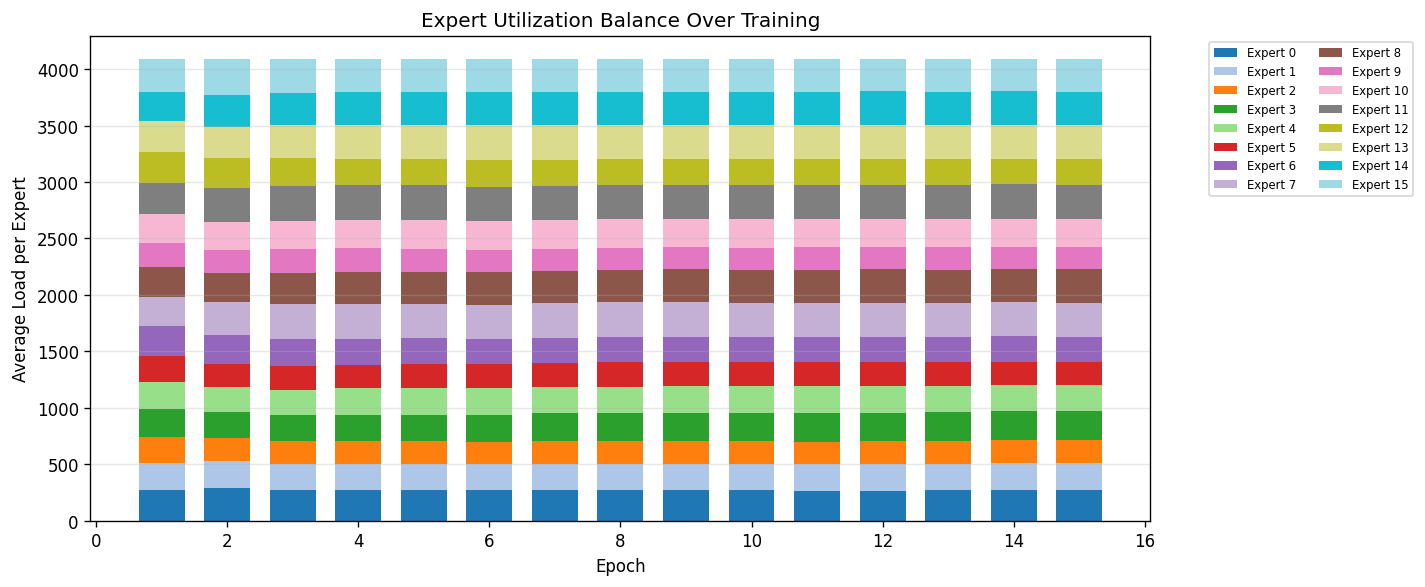

This stacked bar chart shows how the load across experts evolved during training.


In [16]:
fig, ax = plt.subplots(figsize=(12, 5))

util_array = np.array(util_history)
bottom = np.zeros(EPOCHS)
colors = plt.cm.tab20(np.linspace(0, 1, NUM_EXPERTS))

for i in range(NUM_EXPERTS):
    ax.bar(range(1, EPOCHS+1), util_array[:, i], bottom=bottom, 
           color=colors[i], label=f'Expert {i}', width=0.7)
    bottom += util_array[:, i]

ax.set_xlabel('Epoch')
ax.set_ylabel('Average Load per Expert')
ax.set_title('Expert Utilization Balance Over Training')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, ncol=2)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('utilization_balance.png', dpi=120, bbox_inches='tight')
plt.show()

print("This stacked bar chart shows how the load across experts evolved during training.")

## 11. Expert Routing Analysis

In [17]:
sample_text = "To be, or not to be"
sample_chars = [char_to_idx[ch] for ch in sample_text if ch in char_to_idx]
input_tensor = torch.tensor([sample_chars], device=device)

moe_model.eval()
with torch.no_grad():
    logits, gates, load, _ = moe_model(input_tensor)
    gates_np = gates.cpu().numpy()
    
    print(f"Expert routing for sample text: '{sample_text}'")
    print("=" * 60)
    for pos, ch in enumerate(sample_text):
        if ch not in char_to_idx:
            continue
        active_experts = np.where(gates_np[pos] > 0)[0]
        weights = gates_np[pos][active_experts]
        expert_strs = [f"E{ei}({w:.3f})" for ei, w in zip(active_experts, weights)]
        print(f"  Position {pos:2d} ('{ch}'): {' '.join(expert_strs)}")
    
    print(f"\nLoad distribution: {load.cpu().numpy()}")
    print(f"Load min: {load.min().item():.0f}, max: {load.max().item():.0f}, std: {load.std().item():.1f}")

Expert routing for sample text: 'To be, or not to be'
  Position  0 ('T'): E2(0.951) E7(0.049)
  Position  1 ('o'): E2(0.029) E9(0.971)
  Position  2 (' '): E8(0.770) E14(0.230)
  Position  3 ('b'): E10(0.910) E11(0.090)
  Position  4 ('e'): E3(0.881) E12(0.119)
  Position  5 (','): E3(0.913) E13(0.087)
  Position  6 (' '): E1(0.837) E8(0.163)
  Position  7 ('o'): E3(0.016) E9(0.984)
  Position  8 ('r'): E4(0.074) E15(0.926)
  Position  9 (' '): E1(0.616) E8(0.384)
  Position 10 ('n'): E4(0.816) E10(0.184)
  Position 11 ('o'): E9(0.246) E15(0.754)
  Position 12 ('t'): E2(0.660) E7(0.340)
  Position 13 (' '): E8(0.507) E14(0.493)
  Position 14 ('t'): E2(0.979) E11(0.021)
  Position 15 ('o'): E5(0.007) E9(0.993)
  Position 16 (' '): E8(0.516) E14(0.484)
  Position 17 ('b'): E10(0.876) E11(0.124)
  Position 18 ('e'): E3(0.865) E12(0.135)

Load distribution: [0. 2. 4. 4. 2. 1. 0. 2. 5. 4. 3. 3. 2. 1. 3. 2.]
Load min: 0, max: 5, std: 1.5


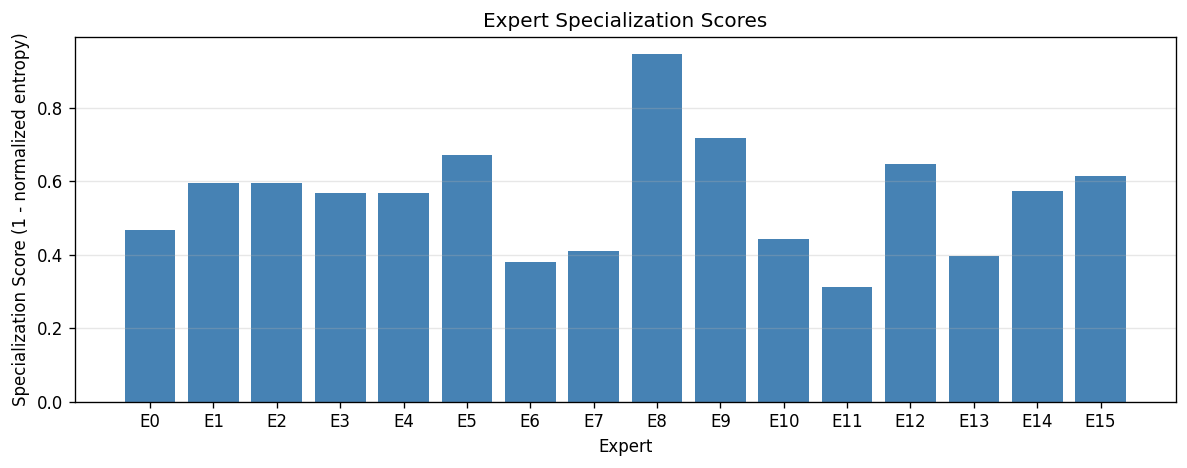


Average specialization: 0.556
Most specialized: Expert 8 (score=0.945)
Least specialized: Expert 11 (score=0.311)


In [18]:
specialization_scores = []
for i in range(NUM_EXPERTS):
    weights = np.array([expert_gate_values[ch][i] for ch in chars])
    if weights.sum() > 0:
        p = weights / weights.sum()
        entropy = -np.sum(p * np.log(p + 1e-10))
        max_entropy = np.log(len(chars))
        specialization = 1 - entropy / max_entropy
    else:
        specialization = 0
    specialization_scores.append(specialization)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(NUM_EXPERTS), specialization_scores, color='steelblue')
ax.set_xlabel('Expert')
ax.set_ylabel('Specialization Score (1 - normalized entropy)')
ax.set_title('Expert Specialization Scores')
ax.set_xticks(range(NUM_EXPERTS))
ax.set_xticklabels([f'E{i}' for i in range(NUM_EXPERTS)])
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('specialization_scores.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"\nAverage specialization: {np.mean(specialization_scores):.3f}")
print(f"Most specialized: Expert {np.argmax(specialization_scores)} (score={max(specialization_scores):.3f})")
print(f"Least specialized: Expert {np.argmin(specialization_scores)} (score={min(specialization_scores):.3f})")

## 12. Text Generation Comparison

In [19]:
def generate_text_moe(model, start_char, length=200, temperature=0.8):
    model.eval()
    chars_generated = [start_char]
    current = torch.tensor([[char_to_idx[start_char]]], device=device)
    h1, h2 = None, None
    with torch.no_grad():
        for _ in range(length):
            if current.size(1) < SEQ_LEN:
                padded = F.pad(current, (SEQ_LEN - current.size(1), 0))
            else:
                padded = current[:, -SEQ_LEN:]
            logits, _, _, (h1, h2) = model(padded, h1, h2)
            last_logits = logits[0, -1] / temperature
            probs = F.softmax(last_logits, dim=-1)
            next_idx = torch.multinomial(probs, 1).item()
            chars_generated.append(idx_to_char[next_idx])
            current = torch.cat([current, torch.tensor([[next_idx]], device=device)], dim=1)
    return ''.join(chars_generated)


def generate_text_dense(model, start_char, length=200, temperature=0.8):
    model.eval()
    chars_generated = [start_char]
    current = torch.tensor([[char_to_idx[start_char]]], device=device)
    h1, h2 = None, None
    with torch.no_grad():
        for _ in range(length):
            if current.size(1) < SEQ_LEN:
                padded = F.pad(current, (SEQ_LEN - current.size(1), 0))
            else:
                padded = current[:, -SEQ_LEN:]
            logits, (h1, h2) = model(padded, h1, h2)
            last_logits = logits[0, -1] / temperature
            probs = F.softmax(last_logits, dim=-1)
            next_idx = torch.multinomial(probs, 1).item()
            chars_generated.append(idx_to_char[next_idx])
            current = torch.cat([current, torch.tensor([[next_idx]], device=device)], dim=1)
    return ''.join(chars_generated)

print("=" * 60)
print("MoE Model Generation:")
print("=" * 60)
print(generate_text_moe(moe_model, 'T', length=300))

print("\n" + "=" * 60)
print("Dense Baseline Generation:")
print("=" * 60)
print(generate_text_dense(dense_model, 'T', length=300))

MoE Model Generation:


ThAR:
How is't!

COMINIUS:
Hald thou canst thou art honest it; for, therefore good a hath flatterers,
A breath to my lord may an eight in his life's walls.

ROMEO:
No, good Margaret, day! Ere it will have you not
He will be beauty, and before your having, the lips;
Shall you do not be govern in this 

Dense Baseline Generation:


The:
No, sir, and the sealous: my brother and bo's good state,
Planternished how her at your husband, thou, leave your voice,
Whose had counsel to I feigned.

POLIXENES:
No some enough, so, being one will be senting
With some gaunt he shall to strength the victory,
he be? these reputure and the world


## 13. Summary & Key Takeaways

In [20]:
print("=" * 70)
print("SUMMARY: Sparsely-Gated Mixture-of-Experts Layer")
print("=" * 70)
print()
print(f"ARCHITECTURE:")
print(f"  - {NUM_EXPERTS} expert sub-networks, top-{TOP_K} gating")
print(f"  - Expert: Linear({D_MODEL}->{D_FF}) -> ReLU -> Linear({D_FF}->{D_MODEL})")
print(f"  - Placed between two LSTM layers in a character-level language model")
print()
print(f"PARAMETERS:")
print(f"  - MoE model total:     {moe_params:,}")
print(f"  - MoE model active:    {moe_active:,} (only top-{TOP_K} experts used per input)")
print(f"  - Dense baseline:      {dense_params:,} (same active compute budget)")
print(f"  - Capacity ratio:      {moe_params/dense_params:.2f}x more total parameters")
print()
print(f"LOAD BALANCING:")
print(f"  - Importance loss (w={W_IMPORTANCE}): prevents gate collapse to few experts")
print(f"  - Load loss (w={W_LOAD}): ensures balanced example distribution")
print()
print(f"RESULTS:")
print(f"  - MoE validation perplexity:   {moe_ppl[-1]:.2f}")
print(f"  - Dense validation perplexity: {dense_ppl[-1]:.2f}")
print(f"  - MoE training time: {moe_time:.1f}s")
print(f"  - Dense training time: {dense_time:.1f}s")
print()
print(f"KEY OBSERVATIONS:")
print(f"  1. The MoE model has {moe_params/dense_params:.2f}x more total parameters than the dense")
print(f"     baseline but uses the same amount of computation per forward pass.")
print(f"  2. Load balancing losses prevent expert collapse -- all {NUM_EXPERTS} experts receive")
print(f"     roughly balanced load throughout training.")
print(f"  3. Different experts specialize in different character types (specialization score")
print(f"     avg: {np.mean(specialization_scores):.3f}), demonstrating meaningful routing.")
print(f"  4. This toy implementation demonstrates the core ideas of Shazeer et al. (2017):")
print(f"     noisy top-k gating, load balancing, and expert specialization -- the same")
print(f"     principles that power modern MoE LLMs like Mixtral 8x7B.")

SUMMARY: Sparsely-Gated Mixture-of-Experts Layer

ARCHITECTURE:
  - 16 expert sub-networks, top-2 gating
  - Expert: Linear(128->256) -> ReLU -> Linear(256->128)
  - Placed between two LSTM layers in a character-level language model

PARAMETERS:
  - MoE model total:     1,339,713
  - MoE model active:    416,833 (only top-2 experts used per input)
  - Dense baseline:      412,609 (same active compute budget)
  - Capacity ratio:      3.25x more total parameters

LOAD BALANCING:
  - Importance loss (w=0.1): prevents gate collapse to few experts
  - Load loss (w=0.1): ensures balanced example distribution

RESULTS:
  - MoE validation perplexity:   4.02
  - Dense validation perplexity: 4.27
  - MoE training time: 242.3s
  - Dense training time: 29.9s

KEY OBSERVATIONS:
  1. The MoE model has 3.25x more total parameters than the dense
     baseline but uses the same amount of computation per forward pass.
  2. Load balancing losses prevent expert collapse -- all 16 experts receive
     roug

In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
